# Customer Churn Classification

เริ่มจากโจทย์ในชีต `Assignment`: ทำนาย `churn` (0/1), เปรียบเทียบอย่างน้อย 2 โมเดล และอธิบาย Accuracy, Precision, Recall, F1 และ Confusion Matrix ข้อมูลมี 1,062 records ตามเอกสารประกอบ

**แนวทาง:** ตรวจคุณภาพข้อมูล → ทำความสะอาด → EDA → แบ่ง train/validation/test → เปรียบเทียบโมเดลด้วย validation → วัดผล test ครั้งเดียว → export pipeline สำหรับ deploy

> รันทุกเซลล์จากบนลงล่าง หากต้องการใช้ไฟล์จากตำแหน่งอื่น ให้แก้ `DATA_PATH` ด้านล่าง


In [37]:
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score,
                             recall_score, roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

RANDOM_STATE = 42
DATA_PATH = Path("C03_customer_churn_classification.xlsx")
if not DATA_PATH.exists():
    DATA_PATH = Path("Customer_Churn/C03_customer_churn_classification.xlsx")
if not DATA_PATH.exists():
    raise FileNotFoundError("วางไฟล์ Excel ไว้ข้างโน้ตบุ๊ก หรือแก้ DATA_PATH ให้ชี้ไปยังไฟล์")

raw = pd.read_excel(DATA_PATH, sheet_name="Raw_Data")
print("Shape:", raw.shape)
raw.head()


Shape: (1062, 8)


,customer_id,months_member,monthly_fee,support_calls,usage_hours_month,late_payments,contract_type,churn
0,C00548,63.0,577.5,2.0,16.0,4.0,Two-Year,0
1,C00831,54.0,509.8,3.0,66.7,5.0,Annual,0
2,C00657,39.0,1081.3,8.0,64.0,3.0,Two-Year,1
3,C00280,48.0,1345.8,4.0,48.3,1.0,TWO-YEAR,1
4,C00152,59.0,625.1,1.0,50.5,2.0,Annual,0


## 1. ทำความเข้าใจและตรวจคุณภาพข้อมูล

`customer_id` เป็น identifier ตาม Data Dictionary จึงไม่ควรป้อนเข้าโมเดล ส่วน `churn` เป็น target การตรวจ outlier ใช้ดูและทำความเข้าใจเท่านั้น: ยังไม่ลบทิ้งโดยอัตโนมัติ เพราะค่าที่สูงหรือต่ำอาจเป็นลูกค้าจริง


In [38]:
print("Data types:")
display(raw.dtypes.to_frame("dtype"))
print("Missing values:")
display(raw.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate customer_id:", raw["customer_id"].duplicated().sum())
print("Target counts:")
display(raw["churn"].value_counts(dropna=False).to_frame("count"))
print("Contract labels:")
print(raw["contract_type"].value_counts(dropna=False))


Data types:


,dtype
customer_id,str
months_member,float64
monthly_fee,float64
support_calls,float64
usage_hours_month,float64
late_payments,float64
contract_type,str
churn,int64


Missing values:


,missing_count
customer_id,0
months_member,2
monthly_fee,7
support_calls,5
usage_hours_month,6
late_payments,4
contract_type,4
churn,0


Duplicate rows: 12
Duplicate customer_id: 12
Target counts:


,count
churn,
1,743
0,319


Contract labels:
contract_type
Two-Year      383
Annual        330
Monthly       327
NaN             4
 Two-Year       4
MONTHLY         4
TWO-YEAR        3
ANNUAL          3
 Monthly        2
 Annual         1
two-year        1
Name: count, dtype: int64


In [39]:
num_cols = ["months_member", "monthly_fee", "support_calls", "usage_hours_month", "late_payments"]
for col in num_cols:
    values = pd.to_numeric(raw[col], errors="coerce")
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    print(f"{col}: min={values.min()}, max={values.max()}, IQR flags={((values < low) | (values > high)).sum()}")


months_member: min=1.0, max=72.0, IQR flags=0
monthly_fee: min=200.0, max=1345.8, IQR flags=5
support_calls: min=0.0, max=9.6, IQR flags=0
usage_hours_month: min=3.0, max=120.0, IQR flags=5
late_payments: min=0.0, max=8.0, IQR flags=0


## 2. ทำความสะอาดข้อมูล

เหตุผล: ตัดแถวซ้ำที่เหมือนกันทั้งหมด, ตัด identifier ออกจาก feature, ทำ `contract_type` ให้สะกดสม่ำเสมอ, แทนค่าว่างหมวดหมู่ด้วย `Unknown`; ค่าว่างตัวเลขจะเติม median ภายใน Pipeline ที่ fit จาก training fold เท่านั้น Target ที่หาย/ไม่ใช่ 0 หรือ 1 ใช้เรียนรู้ไม่ได้จึงตัดออก


In [40]:
df = raw.copy()
df = df.drop_duplicates().copy()
df["contract_type"] = df["contract_type"].astype("string").str.strip().str.lower()
contract_map = {"monthly": "Monthly", "annual": "Annual", "two-year": "Two-Year", "two year": "Two-Year"}
df["contract_type"] = df["contract_type"].map(contract_map).fillna("Unknown")
for col in num_cols + ["churn"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df[df["churn"].isin([0, 1])].copy()
df["churn"] = df["churn"].astype(int)

print("Clean shape:", df.shape)
print("Missing after explicit cleaning (numeric values are imputed in model pipeline):")
display(df.isna().sum().to_frame("missing_count"))
print("Contracts:", df["contract_type"].value_counts(dropna=False).to_dict())


Clean shape: (1050, 8)
Missing after explicit cleaning (numeric values are imputed in model pipeline):


,missing_count
customer_id,0
months_member,2
monthly_fee,7
support_calls,5
usage_hours_month,6
late_payments,4
contract_type,0
churn,0


Contracts: {'Two-Year': 388, 'Annual': 331, 'Monthly': 327, 'Unknown': 4}


## 3. EDA

กราฟต่อไปนี้ช่วยดูสัดส่วน target, ความสัมพันธ์เบื้องต้นของตัวเลขกับ churn และความแตกต่างตามประเภทสัญญา กราฟเหล่านี้เป็นการสำรวจ ไม่ยืนยันเหตุและผล


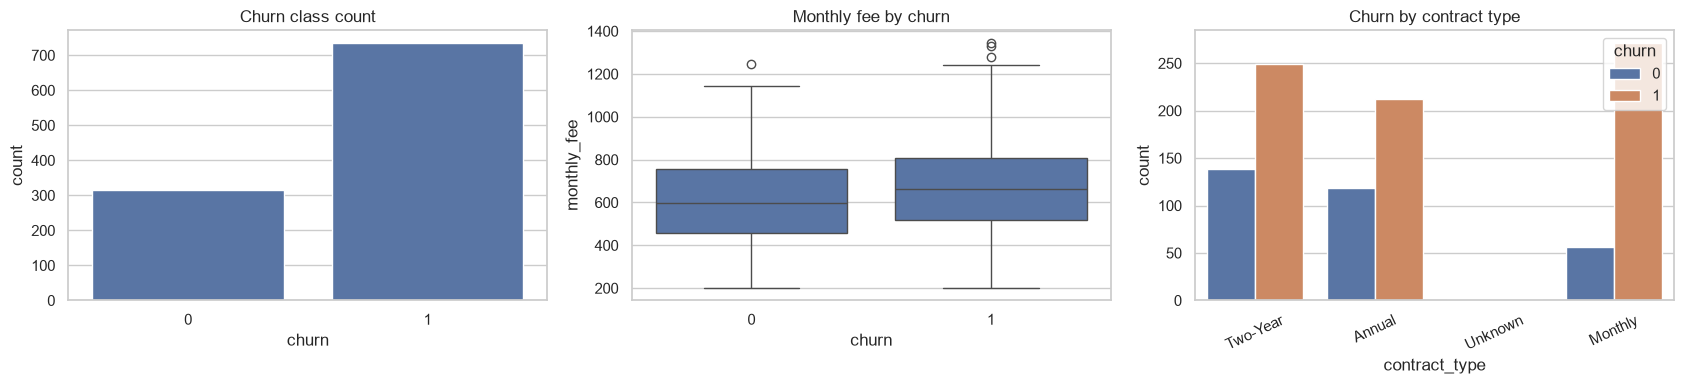

Churn share: 0.699


In [41]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(data=df, x="churn", ax=axes[0])
axes[0].set_title("Churn class count")
sns.boxplot(data=df, x="churn", y="monthly_fee", ax=axes[1])
axes[1].set_title("Monthly fee by churn")
sns.countplot(data=df, x="contract_type", hue="churn", ax=axes[2])
axes[2].set_title("Churn by contract type")
axes[2].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()
print("Churn share:", df["churn"].mean().round(3))


### อ่านกราฟ

- กราฟที่ 1 แสดงจำนวนตัวอย่างของแต่ละ class; หาก class ไม่สมดุล Accuracy อย่างเดียวอาจชวนเข้าใจผิด
- กราฟที่ 2 เปรียบเทียบการกระจายค่าบริการรายเดือนระหว่างกลุ่มที่ churn และไม่ churn; กล่องที่ทับกันมากหมายถึง feature เดี่ยวแยกกลุ่มได้จำกัด
- กราฟที่ 3 เปรียบเทียบจำนวน churn ในแต่ละสัญญา; จำนวนดิบขึ้นกับขนาดกลุ่มด้วย จึงควรดูอัตราส่วนประกอบ

ให้เขียนข้อสังเกตจากกราฟที่ได้จริงหลังรัน และอย่าสรุปว่า feature เป็นสาเหตุของ churn


In [42]:
contract_rate = df.groupby("contract_type", observed=False)["churn"].agg(["mean", "count"]).sort_values("mean", ascending=False)
display(contract_rate.rename(columns={"mean": "churn_rate", "count": "customers"}))


,churn_rate,customers
contract_type,,
Monthly,0.828746,327
Two-Year,0.641753,388
Annual,0.640483,331
Unknown,0.500000,4


## 4. แบ่งข้อมูลและสร้าง preprocessing
 
 แบ่งเป็น train 60%, validation 20%, test 20% แบบ stratified เพื่อรักษาสัดส่วน churn ทุกส่วน ชุด validation ใช้เลือกโมเดล ส่วน test เก็บไว้ประเมินหลังเลือกแล้ว Numeric features ใช้ median imputation และ StandardScaler; หมวดหมู่ใช้ most-frequent imputation และ OneHotEncoder โดย StandardScaler สำคัญกับ KNN เพราะ KNN ใช้ระยะห่างในการหาคลาส ส่วน Random Forest ไม่จำเป็นต้อง scale แต่ใช้ preprocessing ชุดเดียวกันเพื่อให้เปรียบเทียบได้ตรงไปตรงมา


In [43]:
FEATURES = num_cols + ["contract_type"]  # จงใจไม่รวม customer_id
X = df[FEATURES].copy()
y = df["churn"].copy()
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)
print("train/validation/test:", X_train.shape, X_valid.shape, X_test.shape)
print("churn rates:", y_train.mean().round(3), y_valid.mean().round(3), y_test.mean().round(3))

numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
category_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("numeric", numeric_pipe, num_cols),
                                  ("category", category_pipe, ["contract_type"])])


train/validation/test: (630, 6) (210, 6) (210, 6)
churn rates: 0.698 0.7 0.7


## 5. ฝึกและเปรียบเทียบ 3 โมเดล
 
 เปรียบเทียบ Logistic Regression, Random Forest และ K-Nearest Neighbors (KNN) โดยเลือกจาก **validation Macro-F1** เพื่อพิจารณาผลของทั้งสองคลาสเมื่อข้อมูลไม่สมดุล; Precision และ Recall ช่วยอธิบาย trade-off ของการเตือนเกินกับการพลาด churn. KNN ใช้ 11 neighbors และ distance weighting; StandardScaler ช่วยไม่ให้หน่วยวัดที่ใหญ่กว่ามาครอบงำระยะทาง


In [44]:
models = {
    "Logistic Regression": Pipeline([("prep", preprocessor),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("prep", preprocessor),
        ("model", RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))]),
    "K-Nearest Neighbors": Pipeline([("prep", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=11, weights="distance"))]),
}

def score_model(model, X_part, y_part):
    pred = model.predict(X_part)
    proba = model.predict_proba(X_part)[:, 1] if hasattr(model, "predict_proba") else None
    return {"accuracy": accuracy_score(y_part, pred),
            "balanced_accuracy": balanced_accuracy_score(y_part, pred),
            "precision_churn": precision_score(y_part, pred, zero_division=0),
            "recall_churn": recall_score(y_part, pred, zero_division=0),
            "f1_churn": f1_score(y_part, pred, zero_division=0),
            "f1_macro": f1_score(y_part, pred, average="macro", zero_division=0),
            "roc_auc": roc_auc_score(y_part, proba) if proba is not None else np.nan}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
validation_results = pd.DataFrame({name: score_model(m, X_valid, y_valid) for name, m in models.items()}).T
validation_results.loc["Majority baseline"] = score_model(baseline, X_valid, y_valid)
validation_results.sort_values("f1_macro", ascending=False)

,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,f1_macro,roc_auc
Logistic Regression,0.752381,0.741497,0.862595,0.768707,0.812950,0.723376,0.820970
Random Forest,0.738095,0.690476,0.815068,0.809524,0.812287,0.689608,0.774646
K-Nearest Neighbors,0.742857,0.616780,0.756906,0.931973,0.835366,0.624205,0.680866
Majority baseline,0.700000,0.500000,0.700000,1.000000,0.823529,0.411765,0.500000


## 6. ประเมินโมเดลที่เลือกบน test เพียงครั้งเดียว

อย่าเลือกโมเดลจากผล test เพราะจะทำให้ test กลายเป็นส่วนหนึ่งของการปรับโมเดล ตาราง test ด้านล่างใช้รายงานผลสุดท้ายหลังเลือกจาก validation แล้ว


Selected by validation macro-F1: Logistic Regression


,accuracy,balanced_accuracy,precision_churn,recall_churn,f1_churn,f1_macro,roc_auc
Selected model,0.71,0.72,0.864,0.694,0.770,0.688,0.803
Majority baseline,0.70,0.50,0.700,1.000,0.824,0.412,0.500


              precision    recall  f1-score   support

no churn (0)       0.51      0.75      0.61        63
   churn (1)       0.86      0.69      0.77       147

    accuracy                           0.71       210
   macro avg       0.69      0.72      0.69       210
weighted avg       0.76      0.71      0.72       210



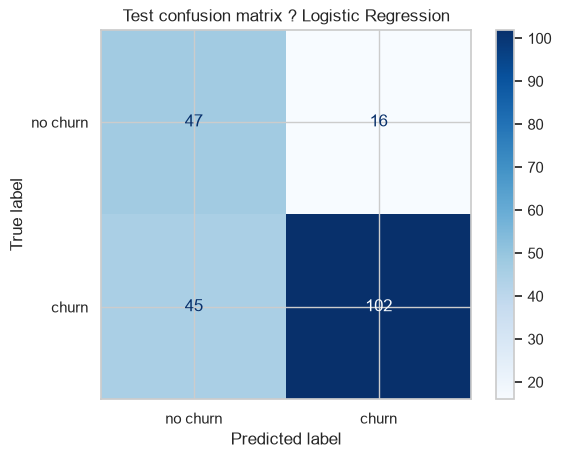

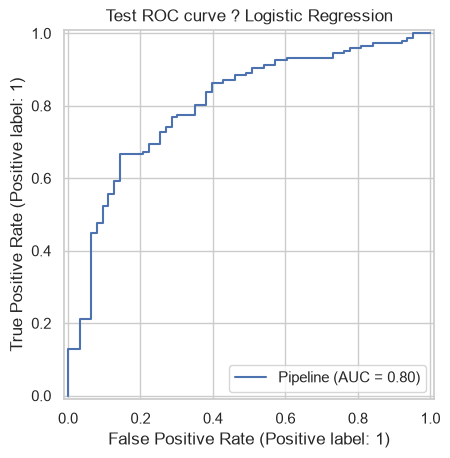

In [45]:
# Select the best of three candidate models using validation macro-F1; baseline is reference only.
best_name = validation_results.loc[list(models), "f1_macro"].idxmax()
best_model = models[best_name]
# Refit the selected model on train + validation; keep test data untouched.
X_trainval = pd.concat([X_train, X_valid])
y_trainval = pd.concat([y_train, y_valid])
best_model.fit(X_trainval, y_trainval)
print("Selected by validation macro-F1:", best_name)
test_scores = score_model(best_model, X_test, y_test)
baseline_test_scores = score_model(baseline, X_test, y_test)
display(pd.DataFrame({"Selected model": test_scores, "Majority baseline": baseline_test_scores}).T.round(3))
test_pred = best_model.predict(X_test)
print(classification_report(y_test, test_pred, target_names=["no churn (0)", "churn (1)"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["no churn", "churn"], cmap="Blues")
plt.title(f"Test confusion matrix ? {best_name}")
plt.show()
if hasattr(best_model, "predict_proba"):
    RocCurveDisplay.from_estimator(best_model, X_test, y_test)
    plt.title(f"Test ROC curve ? {best_name}")
    plt.show()


### วิธีอธิบายผลในบริบท

- **Accuracy:** สัดส่วนที่ทำนายถูกทั้งหมด; อาจดูดีเกินจริงถ้า class ไม่สมดุล
- **Precision (churn=1):** ในรายที่ระบบเตือนว่าจะ churn มีกี่ส่วนที่ churn จริง; precision ต่ำหมายถึงทีมอาจติดต่อลูกค้าผิดกลุ่มมาก
- **Recall (churn=1):** ในผู้ที่ churn จริง ระบบตรวจพบกี่ส่วน; recall ต่ำหมายถึงพลาดลูกค้าที่กำลังจะยกเลิก
- **F1:** ค่าเฉลี่ยเชิงสมดุลของ precision และ recall
- **Confusion matrix:** แถวคือค่าจริง คอลัมน์คือค่าที่ทำนาย; ช่อง churn จริงแต่ทำนาย no churn คือกลุ่มที่พลาด
- **ROC-AUC:** ความสามารถจัดอันดับระหว่างสอง class เมื่อเปลี่ยน threshold; ไม่บอก threshold ที่เหมาะกับธุรกิจโดยลำพัง

ใช้ตัวเลขที่ notebook แสดงจริงเพื่อเขียนสรุป ไม่ใส่ผลลัพธ์ล่วงหน้า


## 7. Export สำหรับ Deploy

บันทึก Pipeline ที่ผ่านการ fit แล้วทั้ง preprocessing และโมเดลไว้ไฟล์เดียว จึงนำข้อมูลดิบที่มีคอลัมน์ feature เดิมเข้า predict ได้ ในการใช้งานจริงควรเก็บเวอร์ชันโมเดลและ dependencies ให้ตรงกัน


In [46]:
MODEL_DIR = DATA_PATH.parent / "model"
MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / "churn_pipeline.joblib"
joblib.dump(best_model, model_path)
print("Saved:", model_path.resolve())


Saved: D:\datascince\Customer_Churn\model\churn_pipeline.joblib


## 8. Deploy สองทางเลือก

- **Streamlit UI:** รัน `streamlit run app.py` แล้วกรอกข้อมูลผ่านหน้าเว็บ
- **FastAPI:** รัน `uvicorn api:app --reload`; เปิด `/docs` เพื่อทดลอง `POST /predict` และ `/health`

ทั้งสองทางเลือกอ่านโมเดลจาก `model/churn_pipeline.joblib` ที่สร้างในเซลล์ก่อนหน้า ก่อนส่งใช้งานจริงให้เพิ่ม authentication, logging ที่ไม่เก็บข้อมูลส่วนบุคคลเกินจำเป็น, monitoring, การตรวจ schema และแนวทาง retrain ตามนโยบายองค์กร
